# Modelagem preditiva e avaliação de classificadores (Atividade_Formativa.ipynb)

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `Atividade_Formativa.ipynb`  

---


In [1]:
# Carregando recursos necessários
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import datasets
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
import sklearn.model_selection as model_selection
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import xgboost as xgb

from warnings import simplefilter
simplefilter(action='ignore', category=FutureWarning)

In [3]:
import pandas as pd
import numpy as np
# loading attribute names
att=pd.read_csv('glass.csv', index_col=-1, nrows=0).columns.tolist()
print(att)
# loading the data
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:,0:9]
y = dataset[:,9]
print(X.shape)

# Dividir os dados em conjunto de treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
(214, 9)


In [5]:
folds=5
knn = KNeighborsClassifier()

parameters = [
  {'n_neighbors': [1, 3, 5, 7, 9, 11],
   'weights': ['uniform', 'distance'],
   'p':[1,2]},
  ]
# GridSearch para customizar os parâmetros sobre base de validação
gs = GridSearchCV(knn, parameters, scoring = 'r2', cv=folds, n_jobs=-1)
gs.fit(X_train, y_train)

df=gs.cv_results_
print("Melhores parâmetros encontrados: ", gs.best_params_)

# Recuperando os melhores parâmetros
model=gs.best_estimator_

# Usando a validação cruzada com 5 folds neste exemplo.
T=5 # número de pastas ou folds
result = model_selection.cross_val_score(knn, X, y, cv=T)

Melhores parâmetros encontrados:  {'n_neighbors': 1, 'p': 2, 'weights': 'uniform'}


Acurácia média: 0.643
Desvio padrão: 0.050
f1: 0.541
Matriz de Confusão


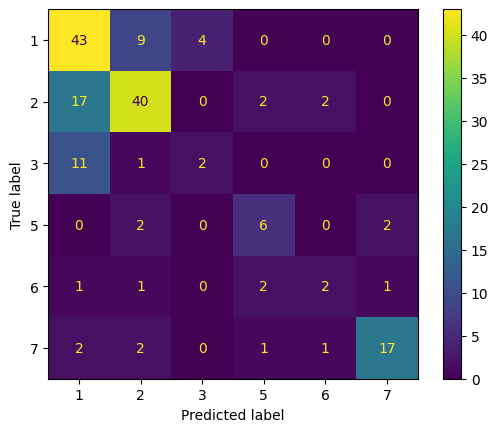

In [6]:
# Instanciando o Bagging
bg = BaggingClassifier(random_state=42)

# Caso queira usar Gridsearch, segue exemplo
# Retirando 20% da base para o GridSearch
X, X_val, y, y_val = train_test_split(X,y,test_size=.2, random_state=42, stratify=y)
# Obs: há mais hiperparâmetros do Bagging que poderiam ser explorados neste caso, segue exemplo abaixo:
bag_param = [{
    'estimator': [knn],               # O KNN treinado previamente
    'n_estimators': [10, 30, 50],          # Quantidade de modelos de base (Bagging classifiers)
    'max_samples': [0.5, 0.7, 1.0],        # Proporção de amostras para cada base learner
    'bootstrap': [True, False],            # Com ou sem reposição das amostras
}]
clf = GridSearchCV(bg, bag_param, scoring = 'accuracy', cv=5)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=[1,2,3,5,6,7])
disp.plot()




Acurácia média: 0.956
Desvio padrão: 0.017
f1: 0.953
Matriz de Confusão


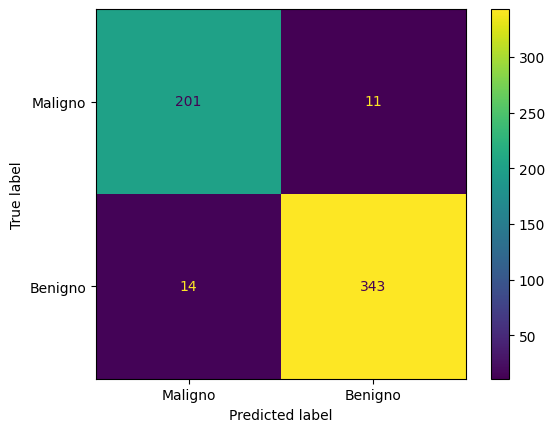

In [ ]:
# Exemplo de outros Algoritmos de ensembles homogêneos (AdaBoost, XGBoost e Random Forest).
# Agora sem uso do GridSearch. Dá para usar GridSearch claro, mas aqui optamos por nao.
# Carregando a base de dados
X,y=load_breast_cancer(return_X_y=True)

# Instanciado a técnica escolhida
# clf = AdaBoostClassifier(n_estimators=100, random_state=42)
xgboost = xgb.XGBClassifier(objective="binary:logistic", random_state=42)
#rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=['Maligno', 'Benigno'])
disp.plot()



